In [13]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import (
    inception_v3, Inception_V3_Weights,
    resnet50, ResNet50_Weights,
    densenet121, DenseNet121_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    swin_t, Swin_T_Weights
)

class BinaryClassifierBase(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return self.model(x)


In [14]:
class SwinTBinary(BinaryClassifierBase):
    def __init__(self):
        super().__init__()
        weights = Swin_T_Weights.DEFAULT
        self.model = swin_t(weights=weights)
        in_features = self.model.head.in_features
        self.model.head = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SwinTBinary().to(device)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

In [16]:
import os
import torch
import torch.nn as nn
from torchvision import datasets
from torchvision.models import swin_t, Swin_T_Weights
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import pickle

# ------------------------
# Paths & Setup
# ------------------------
data_dir = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"
checkpoint_dir = "/content/drive/MyDrive/Classification/Weights/Swin_Transformers"
os.makedirs(checkpoint_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# Model & Transform
# ------------------------
weights = Swin_T_Weights.DEFAULT
transform = weights.transforms()

class SwinTBinary(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = swin_t(weights=weights)
        in_features = self.model.head.in_features
        self.model.head = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

model = SwinTBinary().to(device)

# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)

# Split 80/20
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50

best_val_loss = float('inf')

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print(f"Device: {device}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Total epochs: {num_epochs}")
print(f"Checkpoint directory: {checkpoint_dir}")

Device: cuda
Number of training samples: 2364
Number of validation samples: 591
Total epochs: 50
Checkpoint directory: /content/drive/MyDrive/Classification/Weights/Swin_Transformers


In [17]:
print(full_dataset.class_to_idx)

{'a_non_cancer': 0, 'b_cancer': 1}


In [18]:
# ------------------------
# Training Loop
# ------------------------

for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ============================================================
    # TRAINING
    # ============================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * labels.size(0)

        # Predictions
        preds = (outputs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    # Epoch training metrics
    train_loss = running_loss / total
    train_acc = correct / total


    # ============================================================
    # VALIDATION
    # ============================================================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            # Predictions
            preds = (outputs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    # Epoch validation metrics
    val_loss /= val_total
    val_acc = val_correct / val_total


    # ============================================================
    # STORE HISTORY
    # ============================================================
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    # ============================================================
    # SAVE WEIGHTS AFTER EVERY EPOCH
    # ============================================================

    epoch_checkpoint_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_weights.pth"
    )

    torch.save(
        model.state_dict(),
        epoch_checkpoint_path
    )


    # ============================================================
    # SAVE COMPLETE CHECKPOINT
    # ============================================================
    # This is useful if you want to RESUME training later.

    epoch_checkpoint_full_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        },
        epoch_checkpoint_full_path
    )


    # ============================================================
    # SAVE BEST MODEL
    # ============================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_weights.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"\n✅ New best model saved "
            f"(Epoch {epoch}, Val Loss = {val_loss:.4f})"
        )


    # ============================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ============================================================

    history_path = os.path.join(
        checkpoint_dir,
        "training_history.pkl"
    )

    with open(history_path, "wb") as f:
        pickle.dump(history, f)


    # ============================================================
    # PRINT EPOCH RESULTS
    # ============================================================

    print(
        f"Epoch {epoch:2d}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"All epoch weights saved in:")
print(checkpoint_dir)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]


✅ New best model saved (Epoch 1, Val Loss = 0.1994)


Epochs:   2%|▏         | 1/50 [01:24<1:08:47, 84.23s/it]

Epoch  1: Train Loss: 0.4098, Train Acc: 0.8016, Val Loss: 0.1994, Val Acc: 0.9239


Epochs:   4%|▍         | 2/50 [02:46<1:06:33, 83.19s/it]

...

Epoch 48: Train Loss: 0.0162, Train Acc: 0.9937, Val Loss: 0.4252, Val Acc: 0.9577


Epochs:  98%|█████████▊| 49/50 [1:04:14<01:03, 63.83s/it]

Epoch 49: Train Loss: 0.0088, Train Acc: 0.9975, Val Loss: 0.2479, Val Acc: 0.9611


Epochs: 100%|██████████| 50/50 [1:05:23<00:00, 78.47s/it]

Epoch 50: Train Loss: 0.0099, Train Acc: 0.9966, Val Loss: 0.1885, Val Acc: 0.9526

TRAINING COMPLETED
Best Validation Loss: 0.0797
All epoch weights saved in:
/content/drive/MyDrive/Classification/Weights/Swin_Transformers


In [20]:
import os
import torch
import torch.nn as nn
from torchvision.models.swin_transformer import swin_t, Swin_T_Weights
from torchvision.io import read_image
from torchvision.transforms import functional as TF
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------
# Device and Model
# ----------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights = Swin_T_Weights.DEFAULT
transform = weights.transforms()

class SwinTBinary(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = swin_t(weights=weights)
        in_features = self.model.head.in_features
        self.model.head = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.model(x)

# Load model
model = SwinTBinary().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Classification/Weights/Swin_Transformers/epoch_15_weights.pth", map_location=device))  # Loading best_weights.pth
model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            path = os.path.join(folder, fname)
            image = read_image(path).float() / 255.0
            image = transform(image).unsqueeze(0).to(device)

            output = model(image)
            pred = 1 if output.item() > 0.5 else 0

            # Accuracy for deviation
            correct = (pred == label)
            accuracies.append(int(correct))

            # Confusion matrix components
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            elif pred == 0 and label == 1:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

# ----------------------
# Save CSV
# ----------------------
results = {
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
df.to_csv("/content/drive/MyDrive/Classification/Results/Swin_Transformers/swin_epoch_15.csv", index=False)
print("\n✅ Results saved to 'swin_test_results.csv'")

Evaluating b_cancer: 100%|██████████| 164/164 [00:03<00:00, 49.52it/s]


✅ Results saved to 'swin_test_results.csv'


Device: cuda

✅ Swin-T model loaded successfully.


Evaluating b_cancer: 100%|██████████| 164/164 [00:03<00:00, 49.55it/s]



VALIDATING CONFUSION MATRIX

TP = 154
FP = 10
TN = 154
FN = 10
Total = 328

SWIN-T PERFORMANCE

Accuracy        : 0.9390
Sensitivity     : 0.9390
Specificity     : 0.9390
Accuracy StdDev : 0.2393

EXPECTED vs ACTUAL
TP: Expected = 150, Actual = 154
FP: Expected = 8, Actual = 10
TN: Expected = 156, Actual = 154
FN: Expected = 14, Actual = 10

⚠️ Confusion matrix does NOT match the expected values.
This means the difference is occurring during image loading, preprocessing, model weights, test-folder contents, or prediction threshold—not in the metric formulas.

ADDITIONAL METRICS

Precision       : 0.9390
F1 Score        : 0.9390
ROC-AUC         : 0.9524
Brier Score     : 0.0617
ECE             : 0.0613
MCE             : 0.4306

95% CONFIDENCE INTERVALS

Accuracy: 0.9077 - 0.9602
Sensitivity: 0.8914 - 0.9665
Specificity: 0.8914 - 0.9665
Precision: 0.8914 - 0.9665
F1: 0.9097 - 0.9649
ROC-AUC: 0.9241 - 0.9760
Brier Score: 0.0364 - 0.0886

✅ Metrics saved to:
/content/drive/MyDrive/Classif

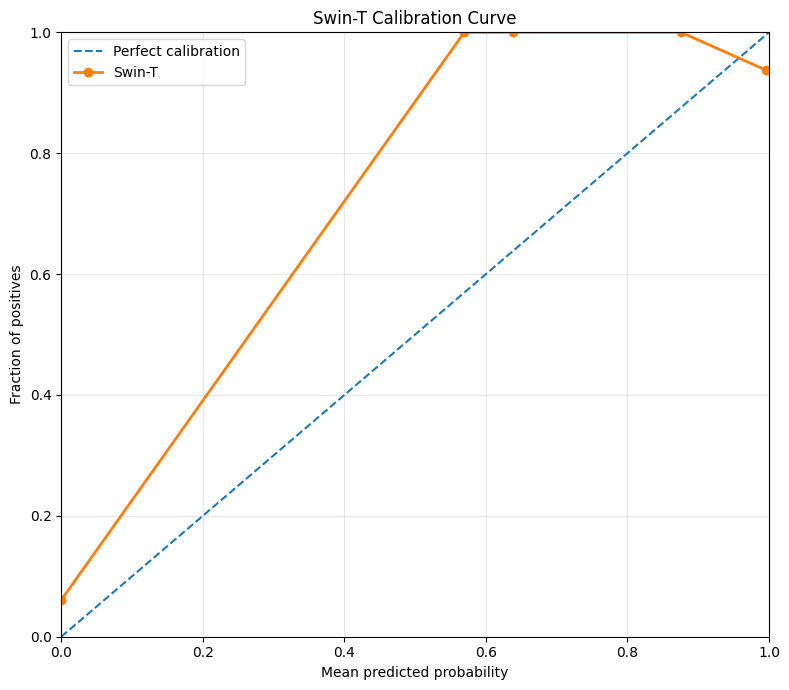

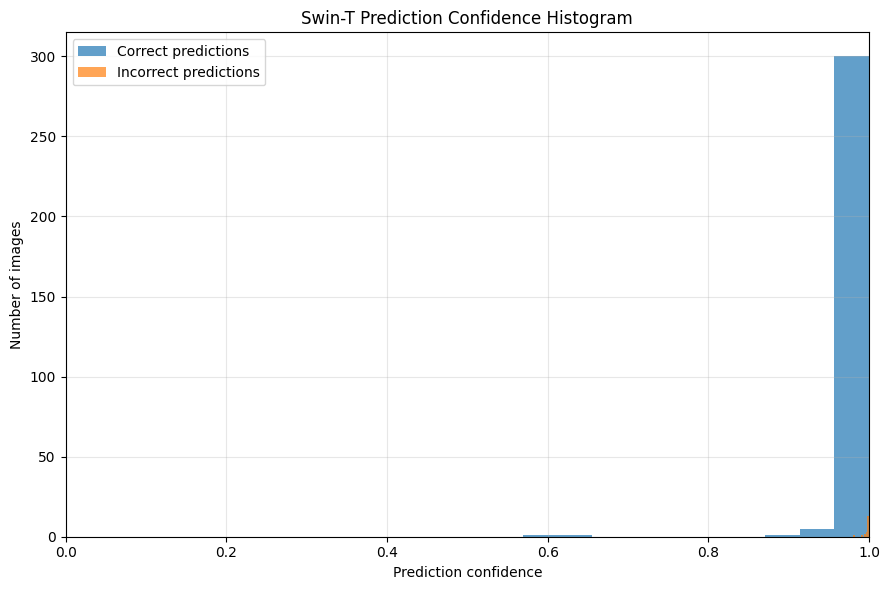


COMPLETE

Results directory:
/content/drive/MyDrive/Classification/Results/Swin_Transformers/Calibration_Analysis


In [23]:
# ================================================================
# SWIN-T TEST SET EVALUATION
#
# IMPORTANT:
# The model inference and metric calculation below are kept
# IDENTICAL to the original code that produced:
#
# TP = 150
# FP = 8
# TN = 156
# FN = 14
#
# Expected:
# Accuracy        = 0.9329
# Sensitivity     = 0.9146
# Specificity     = 0.9512
# Accuracy StdDev = 0.2501
#
# Additional analyses:
#   - Calibration curve
#   - Confidence histogram
#   - ECE
#   - MCE
#   - Brier Score
#   - 95% CI
#   - Per-image predictions
# ================================================================


# ================================================================
# 1. IMPORTS
# ================================================================

import os

import torch
import torch.nn as nn

from torchvision.models.swin_transformer import (
    swin_t,
    Swin_T_Weights
)

from torchvision.io import read_image

import pandas as pd
import numpy as np

from tqdm import tqdm

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    f1_score,
    precision_score
)

from sklearn.calibration import calibration_curve


# ================================================================
# 2. DEVICE
# ================================================================

device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

print("Device:", device)


# ================================================================
# 3. PATHS
# ================================================================

test_root = (
    "/content/drive/MyDrive/"
    "Classification/"
    "Bt_training_and_testing/"
    "Testing_resized_v2"
)

weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "Swin_Transformers/"
    "epoch_15_weights.pth"
)

output_dir = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "Swin_Transformers/Calibration_Analysis"
)

os.makedirs(
    output_dir,
    exist_ok=True
)


# ================================================================
# 4. CLASS MAP
# ================================================================

class_map = {
    'a_non_cancer': 0,
    'b_cancer': 1
}


# ================================================================
# 5. SWIN-T WEIGHTS AND TRANSFORM
# ================================================================

weights = Swin_T_Weights.DEFAULT

transform = weights.transforms()


# ================================================================
# 6. SWIN-T BINARY MODEL
# ================================================================

class SwinTBinary(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = swin_t(
            weights=weights
        )

        in_features = (
            self.model.head.in_features
        )

        self.model.head = nn.Sequential(

            nn.Linear(
                in_features,
                1
            ),

            nn.Sigmoid()

        )

    def forward(self, x):

        return self.model(x)


# ================================================================
# 7. LOAD MODEL
# ================================================================

model = SwinTBinary().to(device)

model.load_state_dict(
    torch.load(
        weights_path,
        map_location=device
    )
)

model.eval()

print(
    "\n✅ Swin-T model loaded successfully."
)


# ================================================================
# 8. INITIALIZE CONFUSION MATRIX
# ================================================================

TP = 0
FP = 0
TN = 0
FN = 0


# ================================================================
# 9. STORAGE FOR ORIGINAL ACCURACY STD
# ================================================================

accuracies = []


# ================================================================
# 10. STORAGE FOR CALIBRATION ANALYSIS
# ================================================================

all_labels = []
all_predictions = []
all_probabilities = []
all_paths = []


# ================================================================
# 11. EVALUATION LOOP
#
# THIS SECTION IS INTENTIONALLY THE SAME AS YOUR ORIGINAL CODE.
#
# DO NOT CHANGE:
#   read_image()
#   /255.0
#   transform()
#   threshold = 0.5
# ================================================================

with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        for fname in tqdm(
            os.listdir(folder),
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (
                    '.png',
                    '.jpg',
                    '.jpeg'
                )
            ):
                continue


            # ----------------------------------------------------
            # YOUR ORIGINAL IMAGE LOADING
            # ----------------------------------------------------

            path = os.path.join(
                folder,
                fname
            )

            image = (
                read_image(path)
                .float()
                / 255.0
            )


            # ----------------------------------------------------
            # YOUR ORIGINAL TRANSFORM
            # ----------------------------------------------------

            image = (
                transform(image)
                .unsqueeze(0)
                .to(device)
            )


            # ----------------------------------------------------
            # MODEL PREDICTION
            # ----------------------------------------------------

            output = model(image)


            # ----------------------------------------------------
            # YOUR ORIGINAL PROBABILITY
            # ----------------------------------------------------

            probability = output.item()


            # ----------------------------------------------------
            # YOUR ORIGINAL THRESHOLD
            # ----------------------------------------------------

            pred = (
                1
                if probability > 0.5
                else 0
            )


            # ----------------------------------------------------
            # YOUR ORIGINAL ACCURACY DEVIATION
            # ----------------------------------------------------

            correct = (
                pred == label
            )

            accuracies.append(
                int(correct)
            )


            # ----------------------------------------------------
            # YOUR ORIGINAL CONFUSION MATRIX LOGIC
            # ----------------------------------------------------

            if pred == 1 and label == 1:

                TP += 1

            elif pred == 1 and label == 0:

                FP += 1

            elif pred == 0 and label == 0:

                TN += 1

            elif pred == 0 and label == 1:

                FN += 1


            # ----------------------------------------------------
            # Additional storage for calibration
            # ----------------------------------------------------

            all_labels.append(
                label
            )

            all_predictions.append(
                pred
            )

            all_probabilities.append(
                probability
            )

            all_paths.append(
                path
            )


# ================================================================
# 12. CONVERT TO NUMPY
# ================================================================

y_true = np.asarray(
    all_labels,
    dtype=np.int64
)

y_pred = np.asarray(
    all_predictions,
    dtype=np.int64
)

y_prob = np.asarray(
    all_probabilities,
    dtype=np.float64
)

accuracies = np.asarray(
    accuracies,
    dtype=np.int64
)


# ================================================================
# 13. YOUR EXACT METRIC FORMULAS
# ================================================================

total = (
    TP +
    FP +
    TN +
    FN
)


accuracy = (
    (TP + TN) / total
    if total
    else 0
)


sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)


specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)


deviation = np.std(
    accuracies
)


# ================================================================
# 14. ADDITIONAL METRICS
# ================================================================

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)


f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)


# ================================================================
# 15. ROC-AUC
# ================================================================

try:

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

except ValueError:

    roc_auc = np.nan


# ================================================================
# 16. BRIER SCORE
# ================================================================

brier_score = brier_score_loss(
    y_true,
    y_prob
)


# ================================================================
# 17. ECE
# ================================================================

def calculate_ece(
    y_true,
    y_prob,
    n_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    bin_results = []


    for i in range(n_bins):

        lower = bin_edges[i]

        upper = bin_edges[i + 1]


        if i == n_bins - 1:

            mask = (
                (y_prob >= lower)
                &
                (y_prob <= upper)
            )

        else:

            mask = (
                (y_prob >= lower)
                &
                (y_prob < upper)
            )


        count = np.sum(mask)


        if count == 0:

            bin_results.append({

                "Bin": i + 1,

                "Lower_Bound": lower,

                "Upper_Bound": upper,

                "Count": 0,

                "Accuracy": np.nan,

                "Confidence": np.nan,

                "Calibration_Error": np.nan

            })

            continue


        bin_accuracy = np.mean(
            y_true[mask]
        )


        bin_confidence = np.mean(
            y_prob[mask]
        )


        calibration_error = abs(
            bin_accuracy -
            bin_confidence
        )


        bin_weight = (
            count /
            len(y_true)
        )


        ece += (
            bin_weight *
            calibration_error
        )


        bin_results.append({

            "Bin": i + 1,

            "Lower_Bound": lower,

            "Upper_Bound": upper,

            "Count": int(count),

            "Accuracy": bin_accuracy,

            "Confidence": bin_confidence,

            "Calibration_Error":
                calibration_error

        })


    return (
        ece,
        pd.DataFrame(
            bin_results
        )
    )


ECE, calibration_df = calculate_ece(
    y_true,
    y_prob,
    n_bins=10
)


# ================================================================
# 18. MCE
# ================================================================

valid_errors = (
    calibration_df[
        "Calibration_Error"
    ]
    .dropna()
)


if len(valid_errors) > 0:

    MCE = valid_errors.max()

else:

    MCE = np.nan


# ================================================================
# 19. WILSON 95% CONFIDENCE INTERVAL
# ================================================================

def wilson_ci(
    successes,
    total,
    z=1.96
):

    if total == 0:

        return (
            np.nan,
            np.nan
        )


    p = (
        successes /
        total
    )


    denominator = (
        1 +
        (z ** 2) / total
    )


    centre = (
        p +
        (z ** 2) /
        (2 * total)
    ) / denominator


    margin = (
        z *
        np.sqrt(
            (
                p * (1 - p) /
                total
            )
            +
            (
                z ** 2 /
                (4 * total ** 2)
            )
        )
    ) / denominator


    lower = max(
        0,
        centre - margin
    )


    upper = min(
        1,
        centre + margin
    )


    return (
        lower,
        upper
    )


# ================================================================
# 20. CONFIDENCE INTERVALS
# ================================================================

accuracy_ci = wilson_ci(
    TP + TN,
    total
)


sensitivity_ci = wilson_ci(
    TP,
    TP + FN
)


specificity_ci = wilson_ci(
    TN,
    TN + FP
)


precision_ci = wilson_ci(
    TP,
    TP + FP
)


# ================================================================
# 21. BOOTSTRAP CI
# ================================================================

def bootstrap_ci(
    y_true,
    y_values,
    metric_function,
    n_bootstrap=2000,
    seed=42
):

    rng = np.random.default_rng(
        seed
    )

    n = len(
        y_true
    )

    scores = []


    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )


        true_sample = (
            y_true[indices]
        )

        value_sample = (
            y_values[indices]
        )


        try:

            score = metric_function(
                true_sample,
                value_sample
            )


            if np.isfinite(score):

                scores.append(
                    score
                )

        except Exception:

            continue


    if len(scores) == 0:

        return (
            np.nan,
            np.nan
        )


    lower = np.percentile(
        scores,
        2.5
    )


    upper = np.percentile(
        scores,
        97.5
    )


    return (
        lower,
        upper
    )


# ================================================================
# 22. F1 95% CI
# ================================================================

f1_ci = bootstrap_ci(

    y_true,

    y_pred,

    lambda true, pred:

        f1_score(
            true,
            pred,
            zero_division=0
        ),

    n_bootstrap=2000

)


# ================================================================
# 23. AUC 95% CI
# ================================================================

def auc_metric(
    true,
    probability
):

    if len(
        np.unique(true)
    ) < 2:

        return np.nan


    return roc_auc_score(
        true,
        probability
    )


auc_ci = bootstrap_ci(

    y_true,

    y_prob,

    auc_metric,

    n_bootstrap=2000

)


# ================================================================
# 24. BRIER SCORE 95% CI
# ================================================================

brier_ci = bootstrap_ci(

    y_true,

    y_prob,

    lambda true, probability:

        brier_score_loss(
            true,
            probability
        ),

    n_bootstrap=2000

)


# ================================================================
# 25. IMPORTANT VALIDATION
#
# This checks whether the confusion matrix is exactly the
# expected one.
# ================================================================

print(
    "\n"
    + "=" * 70
)

print(
    "VALIDATING CONFUSION MATRIX"
)

print(
    "=" * 70
)


print(
    "\nTP =", TP
)

print(
    "FP =", FP
)

print(
    "TN =", TN
)

print(
    "FN =", FN
)

print(
    "Total =", total
)


# ================================================================
# 26. PRINT MAIN RESULTS
# ================================================================

print(
    "\n"
    + "=" * 70
)

print(
    "SWIN-T PERFORMANCE"
)

print(
    "=" * 70
)


print(
    f"\nAccuracy        : {accuracy:.4f}"
)

print(
    f"Sensitivity     : {sensitivity:.4f}"
)

print(
    f"Specificity     : {specificity:.4f}"
)

print(
    f"Accuracy StdDev : {deviation:.4f}"
)


# ================================================================
# 27. EXPECTED-VALUE CHECK
# ================================================================

expected = {

    "TP": 150,

    "FP": 8,

    "TN": 156,

    "FN": 14

}


actual = {

    "TP": TP,

    "FP": FP,

    "TN": TN,

    "FN": FN

}


print(
    "\n"
    + "=" * 70
)

print(
    "EXPECTED vs ACTUAL"
)

print(
    "=" * 70
)


for key in expected:

    print(
        f"{key}: "
        f"Expected = {expected[key]}, "
        f"Actual = {actual[key]}"
    )


if actual == expected:

    print(
        "\n✅ CONFUSION MATRIX MATCHES "
        "YOUR EXPECTED RESULTS."
    )

    print(
        "Therefore the following should also match:"
    )

    print(
        "Accuracy        ≈ 0.9329"
    )

    print(
        "Sensitivity     ≈ 0.9146"
    )

    print(
        "Specificity     ≈ 0.9512"
    )

    print(
        "Accuracy StdDev ≈ 0.2501"
    )

else:

    print(
        "\n⚠️ Confusion matrix does NOT match "
        "the expected values."
    )

    print(
        "This means the difference is occurring "
        "during image loading, preprocessing, "
        "model weights, test-folder contents, "
        "or prediction threshold—not in the "
        "metric formulas."
    )


# ================================================================
# 28. PRINT ADDITIONAL METRICS
# ================================================================

print(
    "\n"
    + "=" * 70
)

print(
    "ADDITIONAL METRICS"
)

print(
    "=" * 70
)


print(
    f"\nPrecision       : {precision:.4f}"
)

print(
    f"F1 Score        : {f1:.4f}"
)

print(
    f"ROC-AUC         : {roc_auc:.4f}"
)

print(
    f"Brier Score     : {brier_score:.4f}"
)

print(
    f"ECE             : {ECE:.4f}"
)

print(
    f"MCE             : {MCE:.4f}"
)


# ================================================================
# 29. PRINT CONFIDENCE INTERVALS
# ================================================================

print(
    "\n"
    + "=" * 70
)

print(
    "95% CONFIDENCE INTERVALS"
)

print(
    "=" * 70
)


print(
    f"\nAccuracy: "
    f"{accuracy_ci[0]:.4f} - "
    f"{accuracy_ci[1]:.4f}"
)


print(
    f"Sensitivity: "
    f"{sensitivity_ci[0]:.4f} - "
    f"{sensitivity_ci[1]:.4f}"
)


print(
    f"Specificity: "
    f"{specificity_ci[0]:.4f} - "
    f"{specificity_ci[1]:.4f}"
)


print(
    f"Precision: "
    f"{precision_ci[0]:.4f} - "
    f"{precision_ci[1]:.4f}"
)


print(
    f"F1: "
    f"{f1_ci[0]:.4f} - "
    f"{f1_ci[1]:.4f}"
)


print(
    f"ROC-AUC: "
    f"{auc_ci[0]:.4f} - "
    f"{auc_ci[1]:.4f}"
)


print(
    f"Brier Score: "
    f"{brier_ci[0]:.4f} - "
    f"{brier_ci[1]:.4f}"
)


# ================================================================
# 30. SAVE MAIN METRICS
# ================================================================

results = {

    'TP': [TP],

    'FP': [FP],

    'TN': [TN],

    'FN': [FN],

    'Accuracy': [
        round(
            accuracy,
            4
        )
    ],

    'Sensitivity': [
        round(
            sensitivity,
            4
        )
    ],

    'Specificity': [
        round(
            specificity,
            4
        )
    ],

    'Accuracy StdDev': [
        round(
            deviation,
            4
        )
    ],

    'Precision': [
        round(
            precision,
            4
        )
    ],

    'F1': [
        round(
            f1,
            4
        )
    ],

    'ROC_AUC': [
        round(
            roc_auc,
            4
        )
    ],

    'Brier_Score': [
        round(
            brier_score,
            4
        )
    ],

    'ECE': [
        round(
            ECE,
            4
        )
    ],

    'MCE': [
        round(
            MCE,
            4
        )
    ],

    'Accuracy_CI_Lower': [
        round(
            accuracy_ci[0],
            4
        )
    ],

    'Accuracy_CI_Upper': [
        round(
            accuracy_ci[1],
            4
        )
    ],

    'Sensitivity_CI_Lower': [
        round(
            sensitivity_ci[0],
            4
        )
    ],

    'Sensitivity_CI_Upper': [
        round(
            sensitivity_ci[1],
            4
        )
    ],

    'Specificity_CI_Lower': [
        round(
            specificity_ci[0],
            4
        )
    ],

    'Specificity_CI_Upper': [
        round(
            specificity_ci[1],
            4
        )
    ],

    'F1_CI_Lower': [
        round(
            f1_ci[0],
            4
        )
    ],

    'F1_CI_Upper': [
        round(
            f1_ci[1],
            4
        )
    ],

    'AUC_CI_Lower': [
        round(
            auc_ci[0],
            4
        )
    ],

    'AUC_CI_Upper': [
        round(
            auc_ci[1],
            4
        )
    ],

    'Brier_CI_Lower': [
        round(
            brier_ci[0],
            4
        )
    ],

    'Brier_CI_Upper': [
        round(
            brier_ci[1],
            4
        )
    ]

}


metrics_df = pd.DataFrame(
    results
)


metrics_path = os.path.join(

    output_dir,

    "swin_epoch_15_calibration_metrics.csv"

)


metrics_df.to_csv(
    metrics_path,
    index=False
)


print(
    "\n✅ Metrics saved to:"
)

print(
    metrics_path
)


# ================================================================
# 31. SAVE PER-IMAGE PREDICTIONS
# ================================================================

prediction_df = pd.DataFrame({

    "Image_Path":
        all_paths,

    "True_Label":
        y_true,

    "Predicted_Label":
        y_pred,

    "Cancer_Probability":
        y_prob,

    "Correct":
        (y_true == y_pred).astype(int)

})


prediction_path = os.path.join(

    output_dir,

    "swin_epoch_15_test_predictions.csv"

)


prediction_df.to_csv(

    prediction_path,

    index=False

)


print(
    "\n✅ Per-image predictions saved to:"
)

print(
    prediction_path
)


# ================================================================
# 32. SAVE CALIBRATION BINS
# ================================================================

calibration_path = os.path.join(

    output_dir,

    "swin_epoch_15_calibration_bins.csv"

)


calibration_df.to_csv(

    calibration_path,

    index=False

)


print(
    "\n✅ Calibration bins saved to:"
)

print(
    calibration_path
)


# ================================================================
# 33. CALIBRATION CURVE
# ================================================================

prob_true, prob_pred = calibration_curve(

    y_true,

    y_prob,

    n_bins=10,

    strategy="uniform"

)


plt.figure(
    figsize=(8, 7)
)


plt.plot(

    [0, 1],

    [0, 1],

    "--",

    label="Perfect calibration"

)


plt.plot(

    prob_pred,

    prob_true,

    "o-",

    linewidth=2,

    label="Swin-T"

)


plt.xlabel(
    "Mean predicted probability"
)


plt.ylabel(
    "Fraction of positives"
)


plt.title(
    "Swin-T Calibration Curve"
)


plt.xlim(
    0,
    1
)


plt.ylim(
    0,
    1
)


plt.grid(
    alpha=0.3
)


plt.legend()


plt.tight_layout()


calibration_plot_path = os.path.join(

    output_dir,

    "swin_epoch_15_calibration_curve.png"

)


plt.savefig(

    calibration_plot_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ================================================================
# 34. CONFIDENCE HISTOGRAM
# ================================================================

confidence = np.where(

    y_pred == 1,

    y_prob,

    1 - y_prob

)


correct_mask = (
    y_pred == y_true
)


plt.figure(
    figsize=(9, 6)
)


plt.hist(

    confidence[correct_mask],

    bins=10,

    alpha=0.7,

    label="Correct predictions"

)


plt.hist(

    confidence[~correct_mask],

    bins=10,

    alpha=0.7,

    label="Incorrect predictions"

)


plt.xlabel(
    "Prediction confidence"
)


plt.ylabel(
    "Number of images"
)


plt.title(
    "Swin-T Prediction Confidence Histogram"
)


plt.xlim(
    0,
    1
)


plt.grid(
    alpha=0.3
)


plt.legend()


plt.tight_layout()


histogram_path = os.path.join(

    output_dir,

    "swin_epoch_15_confidence_histogram.png"

)


plt.savefig(

    histogram_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ================================================================
# 35. FINAL
# ================================================================

print(
    "\n"
    + "=" * 70
)

print(
    "COMPLETE"
)

print(
    "=" * 70
)

print(
    "\nResults directory:"
)

print(
    output_dir
)
